# TráficoIA · Reconocimiento de señales
Entrenamos una red convolucional propia en PyTorch para distinguir las 12 clases de GTSRB seleccionadas en la propuesta. Incluimos cinco límites de velocidad para estudiar hasta qué punto la red distingue sus números. Ejecutar las celdas en orden con el entorno `proyecto_ia`. Si faltan imágenes, ejecutar `python src/descargar_datos.py --imagenes` desde la raíz.

Datos: J. Stallkamp, M. Schlipsing, J. Salmen y C. Igel (2012), *Man vs. computer: Benchmarking machine learning algorithms for traffic sign recognition*. [GTSRB](https://benchmark.ini.rub.de/gtsrb_news.html).

In [1]:
from pathlib import Path
import copy
import sys
if not (Path.cwd() / "src").is_dir():
    sys.path.insert(0, str(Path.cwd().parent))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import DataLoader
from src import config, cnn

torch.manual_seed(config.SEMILLA)
torch.set_num_threads(min(torch.get_num_threads(), 3))
dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
nombres = [config.NOMBRES_CLASES[i] for i in config.SUBSET_CLASES]
config.FIGURAS.mkdir(parents=True, exist_ok=True)
config.MODELOS.mkdir(parents=True, exist_ok=True)
print("PyTorch", torch.__version__, "·", dispositivo)

PyTorch 2.7.1+cpu · cpu


## Preparación de imágenes
Para cada clase, reservamos aproximadamente el 20 % de sus secuencias de entrenamiento para validar. La prueba usa las etiquetas oficiales. Cada imagen se convierte a RGB, se redimensiona a 32 × 32 y se normaliza al intervalo [−1, 1]. Solo durante el entrenamiento aplicamos pequeños giros, desplazamientos y cambios de brillo.

In [2]:
filas_train, filas_val, filas_test = cnn.particiones()
def pistas(filas):
    return {(y, ruta.stem.split("_")[0]) for ruta, y in filas}
assert pistas(filas_train).isdisjoint(pistas(filas_val))
resumen = {}
for etiqueta, filas in zip(["Entrenamiento", "Validación", "Prueba"], [filas_train, filas_val, filas_test]):
    resumen[etiqueta] = np.bincount([y for _, y in filas], minlength=len(nombres))
conteos = pd.DataFrame(resumen, index=nombres)
assert (conteos > 0).all().all()
display(conteos)
print(conteos.sum())
train = DataLoader(cnn.dataset(filas_train), batch_size=128, shuffle=True)
val = DataLoader(cnn.dataset(filas_val), batch_size=128)
test = DataLoader(cnn.dataset(filas_test), batch_size=128)

Entrenamiento    10290
Validación        2550
Prueba            6270
dtype: int64


,Entrenamiento,Validación,Prueba
Límite 30 km/h,1200,300,720
Límite 50 km/h,1200,300,750
Límite 60 km/h,780,180,450
Límite 70 km/h,1050,270,660
Límite 80 km/h,1020,240,630
Ceda el paso,1140,300,720
Alto,420,120,270
Entrada prohibida,600,150,360
Precaución general,660,150,390
Obras en la vía,810,210,480


## Arquitectura y entrenamiento
Los tres bloques Conv2d–ReLU–MaxPool reducen el tamaño espacial de 32 a 4 píxeles por lado y aprenden 16, 32 y 48 filtros. Una capa densa de 96 unidades con dropout de 0.25 alimenta las 12 salidas. Entrenamos con Adam y entropía cruzada. Conservamos la época con menor pérdida de validación.

In [3]:
modelo = cnn.Clasificador(len(nombres)).to(dispositivo)
opt = torch.optim.Adam(modelo.parameters(), lr=0.001)
historial = []
mejor_perdida = float("inf")
for ep in range(1, 16):
    lt, at = cnn.epoca(modelo, train, dispositivo, opt)
    lv, av = cnn.epoca(modelo, val, dispositivo)
    historial.append((ep, lt, lv, at, av))
    if lv < mejor_perdida:
        mejor_perdida, mejor_epoca = lv, ep
        mejores_pesos = copy.deepcopy(modelo.state_dict())
    print(f"Época {ep:2d} · pérdida val {lv:.3f} · exactitud val {av:.1%}")
modelo.load_state_dict(mejores_pesos)
ruta_modelo = config.MODELOS / "cnn_senales.pt"
torch.save({"pesos": modelo.cpu().state_dict(), "clases": config.SUBSET_CLASES,
            "nombres": nombres, "tamano": 32, "epoca": mejor_epoca}, ruta_modelo)
print("Época seleccionada:", mejor_epoca)

Época  1 · pérdida val 1.634 · exactitud val 42.5%
Época  2 · pérdida val 1.149 · exactitud val 54.2%
Época  3 · pérdida val 1.078 · exactitud val 54.5%
Época  4 · pérdida val 0.947 · exactitud val 64.0%
Época  5 · pérdida val 0.900 · exactitud val 64.8%
Época  6 · pérdida val 0.799 · exactitud val 70.6%
Época  7 · pérdida val 0.797 · exactitud val 67.6%
Época  8 · pérdida val 0.747 · exactitud val 72.5%
Época  9 · pérdida val 0.660 · exactitud val 75.1%
Época 10 · pérdida val 0.643 · exactitud val 75.9%
Época 11 · pérdida val 0.560 · exactitud val 79.2%
Época 12 · pérdida val 0.600 · exactitud val 77.3%
Época 13 · pérdida val 0.519 · exactitud val 81.2%
Época 14 · pérdida val 0.471 · exactitud val 82.5%
Época 15 · pérdida val 0.578 · exactitud val 81.0%
Época seleccionada: 14


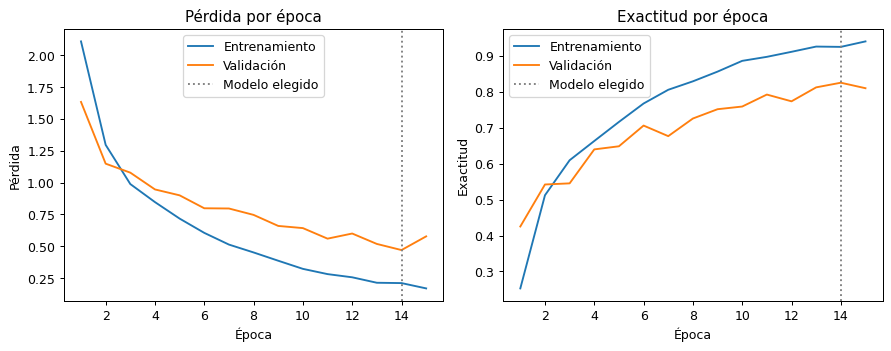

In [4]:
curvas = pd.DataFrame(historial, columns=["época", "pérdida_ent", "pérdida_val", "exactitud_ent", "exactitud_val"]).set_index("época")
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metrica in zip(ejes, ["pérdida", "exactitud"]):
    ax.plot(curvas.index, curvas[metrica + "_ent"], label="Entrenamiento")
    ax.plot(curvas.index, curvas[metrica + "_val"], label="Validación")
    ax.axvline(mejor_epoca, linestyle=":", color="gray", label="Modelo elegido")
    ax.set(xlabel="Época", ylabel=metrica.capitalize(), title=metrica.capitalize() + " por época")
    ax.legend()
fig.tight_layout()
fig.savefig(config.FIGURAS / "cnn_curvas.png", dpi=140)
plt.show()

## Prueba con el modelo guardado
Volvemos a cargar el archivo de pesos. Las filas de la matriz representan la señal real y las columnas, la predicción. Los valores son conteos de imágenes.

Exactitud oficial de prueba: 81.69% (5122/6270)


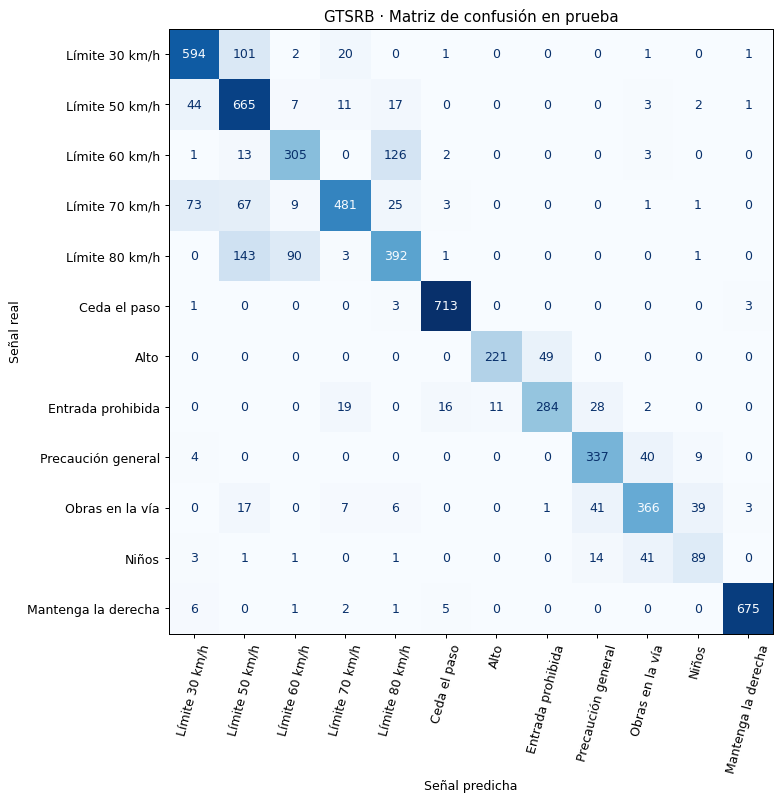

In [5]:
guardado = torch.load(ruta_modelo, map_location=dispositivo, weights_only=True)
red = cnn.Clasificador(len(guardado["clases"])).to(dispositivo)
red.load_state_dict(guardado["pesos"])
red.eval()
with torch.inference_mode():
    pred = torch.cat([red(cnn.normalizar(x.to(dispositivo))).argmax(1).cpu() for x, _ in test]).numpy()
real = test.dataset.tensors[1].numpy()
matriz = confusion_matrix(real, pred, labels=np.arange(len(nombres)))
print(f"Exactitud oficial de prueba: {(pred == real).mean():.2%} ({(pred == real).sum()}/{len(real)})")
fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay(matriz, display_labels=nombres).plot(ax=ax, cmap="Blues", xticks_rotation=75, colorbar=False, values_format="d")
ax.set(title="GTSRB · Matriz de confusión en prueba", xlabel="Señal predicha", ylabel="Señal real")
fig.tight_layout()
fig.savefig(config.FIGURAS / "cnn_confusion.png", dpi=140)
plt.show()

Confusión más frecuente: Límite 80 km/h → Límite 50 km/h, 143 de 630 imágenes de la clase real.


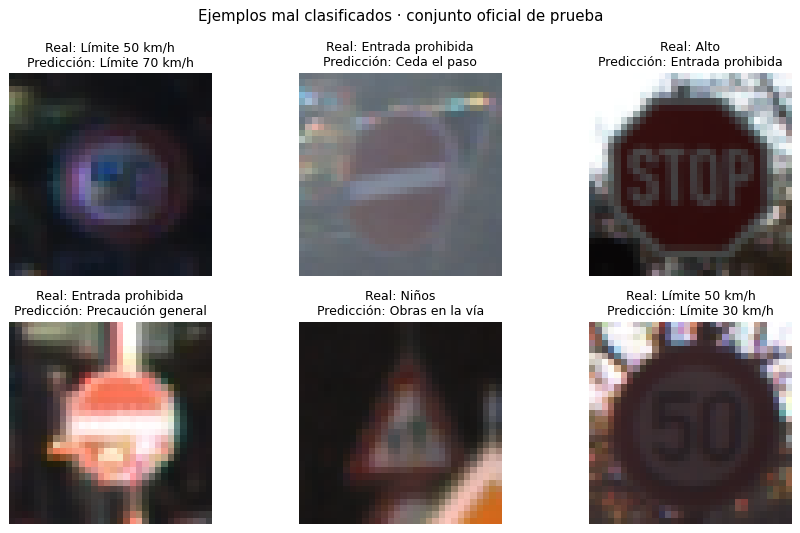

In [6]:
errores = np.flatnonzero(pred != real)
pares = matriz.copy()
np.fill_diagonal(pares, 0)
if errores.size:
    i, j = np.unravel_index(pares.argmax(), pares.shape)
    print(f"Confusión más frecuente: {nombres[i]} → {nombres[j]}, {pares[i, j]} de {matriz[i].sum()} imágenes de la clase real.")
    muestra = np.random.default_rng(config.SEMILLA).choice(errores, min(6, len(errores)), replace=False)
    fig, ejes = plt.subplots(2, 3, figsize=(10, 6))
    for ax in ejes.flat:
        ax.axis("off")
    for ax, k in zip(ejes.flat, muestra):
        ax.imshow(test.dataset.tensors[0][k].permute(1, 2, 0))
        ax.set_title(f"Real: {nombres[real[k]]}\nPredicción: {nombres[pred[k]]}", fontsize=10)
    fig.suptitle("Ejemplos mal clasificados · conjunto oficial de prueba")
    fig.tight_layout()
    fig.savefig(config.FIGURAS / "cnn_errores.png", dpi=140)
    plt.show()
else:
    print("La red acertó todas las imágenes de prueba.")

## Interpretación de la corrida entregada
En 15 épocas, la exactitud de validación pasó del 42.5 % al 81.0 %. La pérdida más baja apareció en la época 14 (0.471), con 82.5 % de exactitud. En la época 15 la pérdida volvió a subir a 0.578, por lo que se conservaron los pesos de la época anterior.

En el conjunto oficial, el modelo acertó 5,122 de 6,270 imágenes (81.69 %). La confusión más frecuente fue leer un límite de 80 km/h como 50 km/h. Ocurrió en 143 de las 630 imágenes de 80 km/h (22.7 %). Ambos límites comparten forma y borde, y para diferenciarlos la red necesita conservar el detalle del primer dígito. La matriz identifica el patrón de error, aunque por sí sola no demuestra su causa.

## Mejora propuesta
Probar entradas de 48 × 48 para conservar detalles pequeños, ajustando la dimensión de la primera capa densa. Comparar ambos tamaños con las mismas secuencias de validación y revisar las confusiones por clase antes de elegir el modelo.